# 11. Model Explainability Using SHAP

## 1. Introduction

Model explainability is important in financial applications
because predictions may influence decisions involving money
and customer accounts.

SHAP (SHapley Additive exPlanations) is a model explainability
method based on Shapley values from cooperative game theory.

It estimates the contribution of individual features
to a model prediction.

This notebook investigates:

- Global Feature Importance
- SHAP Summary Plot
- Individual Prediction Explanation
- Feature Contribution Analysis

SHAP explanations describe model behavior and do not establish
causal relationships.

In [24]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

from src.config import (
    CLEANED_DATA_PATH,
    TARGET_COLUMN,
    RANDOM_STATE,
    TUNED_MODEL_PATH,
    FIGURES_DIR,
)

from src.explainability import (
    explain_model,
    get_feature_importance,
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

## 2. Loading the Final Model

The final tuned model is loaded.

The cleaned dataset is used to obtain representative
transaction samples for explainability analysis.

The model's saved preprocessing pipeline is reused
to ensure consistency with training.

In [25]:
df = pd.read_csv(
    CLEANED_DATA_PATH
)

X = df.drop(
    columns=[TARGET_COLUMN]
)

y = df[TARGET_COLUMN]

model = joblib.load(
    TUNED_MODEL_PATH
)

print("Dataset Shape:", X.shape)

print("Model loaded successfully.")

display(X.head())

Dataset Shape: (284807, 30)
Model loaded successfully.


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99


## 3. Global Feature Importance

Global feature importance summarizes the relative importance
of individual features in the trained tree-based model.

The analysis identifies features that contribute most
to the model's predictive decisions.

Feature importance does not explain the direction of
a feature's effect and should not be interpreted causally.

In [26]:
feature_importance = get_feature_importance(
    model
)

display(
    feature_importance.head(20)
)

,feature,importance
0,V14,0.182442
1,V10,0.114625
2,V4,0.098209
3,V12,0.096305
4,V17,0.083009
5,V11,0.081162
6,V16,0.045576
7,V3,0.040005
8,V7,0.038296
9,V2,0.024035


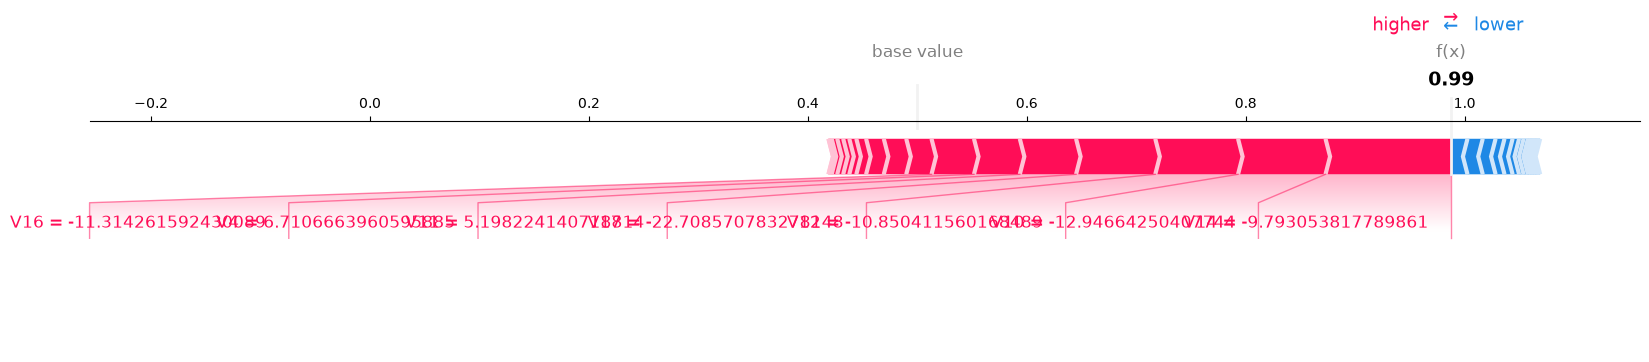

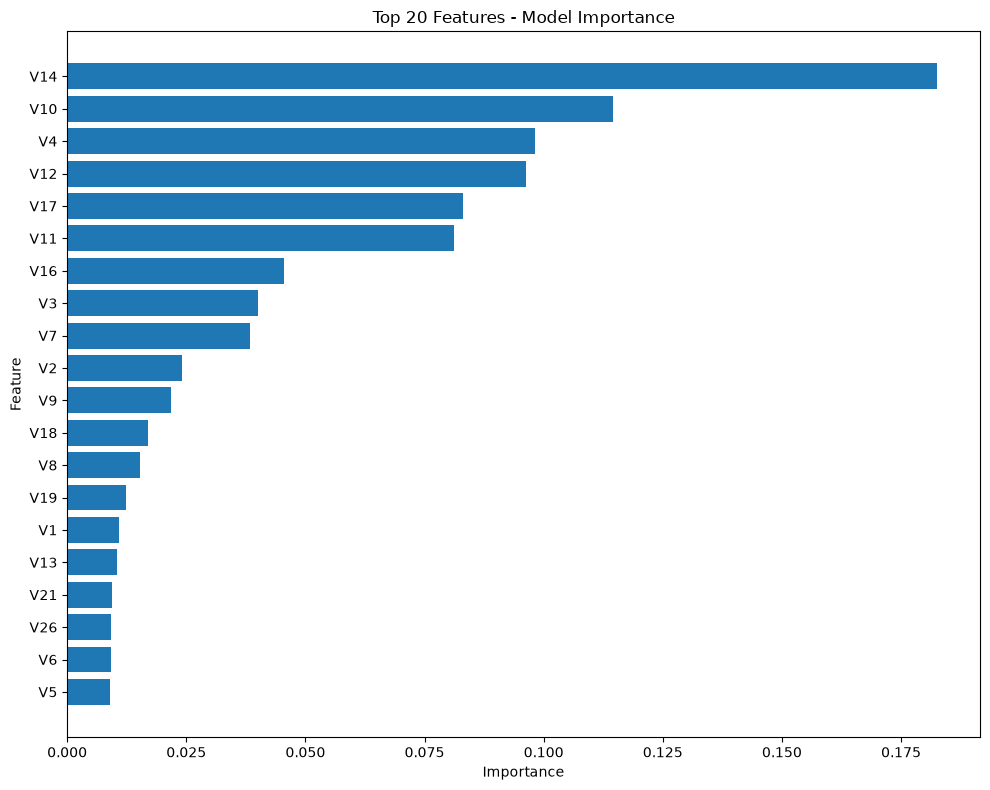

In [27]:
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.title("Top 20 Features - Model Importance")

plt.xlabel("Importance")

plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. SHAP Summary Plot

The SHAP summary plot provides a global explanation
of the model.

Each point represents one observation.

The horizontal position represents the SHAP value:

- Positive SHAP values increase the model output.
- Negative SHAP values decrease the model output.

The feature value is represented by the point color.

The summary plot helps identify which features have
the strongest influence on model predictions.

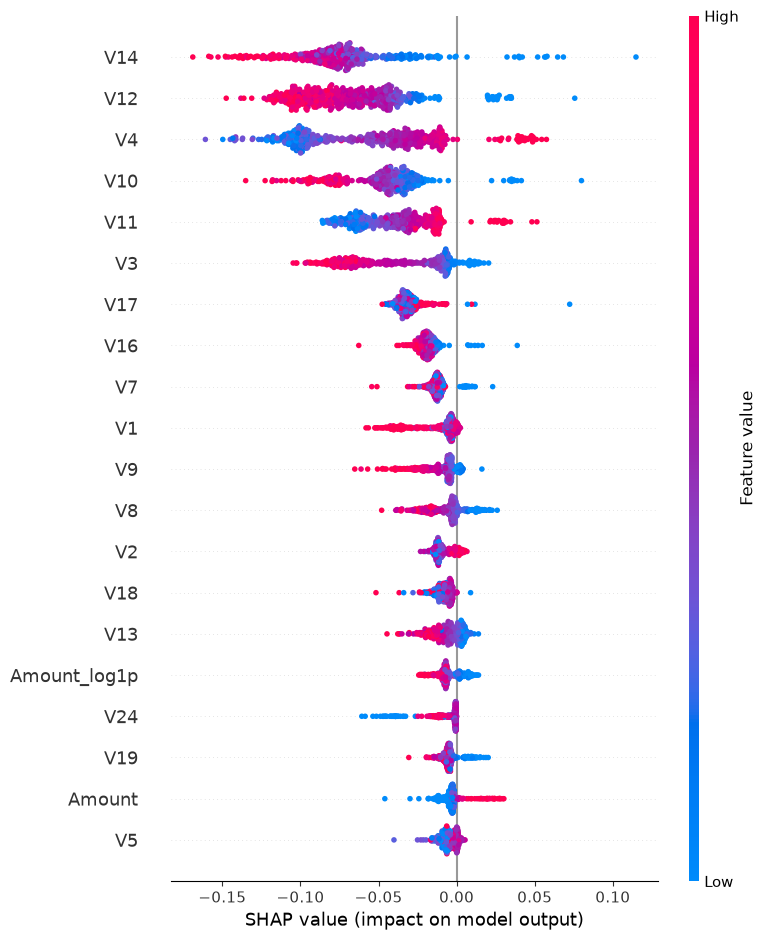

SHAP values shape: (500, 32)


In [28]:
# A representative sample is used to reduce computation time.

X_sample = X.sample(
    n=min(500, len(X)),
    random_state=RANDOM_STATE
)

shap_values = explain_model(
    model,
    X_sample,
    max_samples=500
)

print("SHAP values shape:", np.array(shap_values).shape)

## 5. Individual Prediction Explanation

Global explanations describe general model behavior.

However, individual transaction explanations can provide
additional insight into a specific prediction.

The contribution of each feature is examined for
a selected transaction.

A positive contribution supports the model's positive-class
output, while a negative contribution moves it away from
the positive-class output, subject to the explainer's
output scale and model configuration.

In [29]:
# Select one transaction for explanation.

transaction_index = X_sample.index[0]

single_transaction = X.loc[
    [transaction_index]
]

actual_class = y.loc[
    transaction_index
]

print("Transaction Index:", transaction_index)

print("Actual Class:", actual_class)

display(single_transaction)

Transaction Index: 43428
Actual Class: 1


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
43428,41505.0,-16.526507,8.584972,-18.649853,9.505594,-13.793819,-2.832404,-16.701694,7.517344,-8.507059,...,-1.514923,1.190739,-1.12767,-2.358579,0.673461,-1.4137,-0.462762,-2.018575,-1.042804,364.19


In [30]:
import shap

feature_engineer = model.named_steps[
    "feature_engineering"
]

preprocessor = model.named_steps[
    "preprocessing"
]

classifier = model.named_steps[
    "model"
]

single_features = feature_engineer.transform(
    single_transaction
)

single_processed = preprocessor.transform(
    single_features
)

feature_names = feature_engineer.get_feature_names_out()

explainer = shap.TreeExplainer(
    classifier
)

single_shap_values = explainer.shap_values(
    single_processed
)

if isinstance(single_shap_values, list):

    single_shap_values = single_shap_values[-1]

elif (
    isinstance(single_shap_values, np.ndarray)
    and single_shap_values.ndim == 3
):

    single_shap_values = single_shap_values[:, :, -1]

base_value = np.asarray(
    explainer.expected_value
).reshape(-1)[-1].item()

single_explanation = shap.Explanation(
    values=single_shap_values[0],
    base_values=base_value,
    data=single_processed[0],
    feature_names=feature_names,
)

print("Individual SHAP values calculated.")

Individual SHAP values calculated.


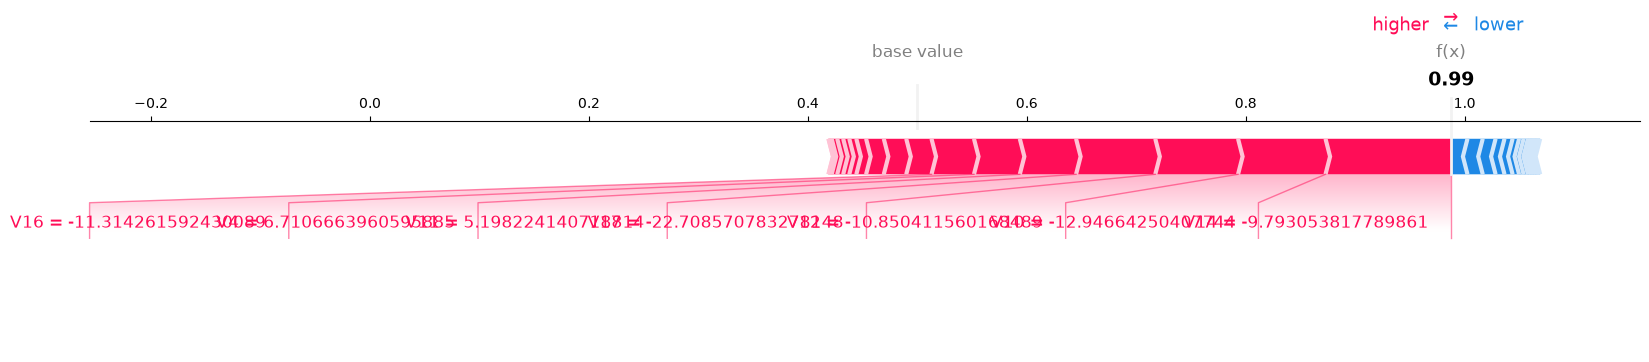

In [31]:
shap.plots.force(
    single_explanation,
    matplotlib=True,
    show=False
)

plt.savefig(
    FIGURES_DIR / "individual_shap_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Feature Contribution Table

The SHAP values are ranked by their absolute magnitude.

Features with larger absolute SHAP values have a stronger
contribution to the selected prediction.

The sign indicates the direction of the contribution
on the explainer's output scale.

In [32]:
contributions = pd.DataFrame({
    "Feature": feature_names,
    "Feature Value": single_processed[0],
    "SHAP Value": single_shap_values[0],
})

contributions["Absolute SHAP"] = (
    contributions["SHAP Value"].abs()
)

contributions = contributions.sort_values(
    by="Absolute SHAP",
    ascending=False
)

display(
    contributions.head(15)
)

,Feature,Feature Value,SHAP Value,Absolute SHAP
14,V14,-9.793054,0.114806,0.114806
10,V10,-12.946643,0.079907,0.079907
12,V12,-10.850412,0.075620,0.075620
17,V17,-22.708571,0.072365,0.072365
11,V11,5.198224,0.051396,0.051396
4,V4,6.710666,0.041867,0.041867
16,V16,-11.314262,0.038802,0.038802
7,V7,-13.682810,0.023075,0.023075
3,V3,-12.278107,0.020509,0.020509
9,V9,-7.741300,0.016163,0.016163


## 7. Explainability Limitations

SHAP provides explanations of model behavior.

However, the following limitations should be considered:

1. SHAP values do not establish causality.
2. Correlated features may affect the allocation of contributions.
3. Explanations depend on the selected background and model.
4. A feature's importance does not necessarily indicate
   that it can independently identify fraud.
5. Model explanations should be interpreted together with
   domain knowledge and validation results.

## 8. Final Conclusion

The explainability stage provides insights into how
the final model generates fraud predictions.

The final report should discuss:

- The most influential features.
- The general direction of feature contributions.
- Differences between global and individual explanations.
- Limitations of model explainability.

The findings should be interpreted as explanations
of model behavior rather than causal evidence.

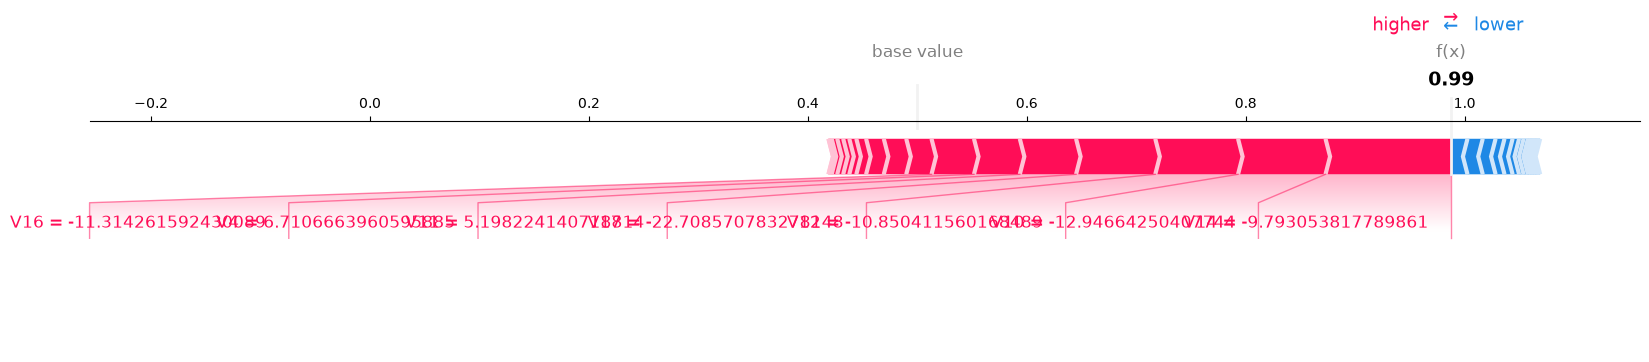

In [33]:
shap.plots.force(
    single_explanation,
    matplotlib=True,
    show=False
)